# Свёрточная нейронная сеть на PyTorch: пример от начала до конца

**Команда 22 · Сверточные нейронные сети (CNN)**

Этот блокнот — самодостаточная версия основного примера из презентации: он не использует
другие файлы каталога `src/` и читается сверху вниз. Мы:

1. загрузим набор **Fashion-MNIST** (70 000 чёрно-белых картинок одежды 28×28, 10 классов);
2. посмотрим, что делает одна операция свёртки;
3. соберём свёрточную сеть **SimpleCNN** и разберём форму тензора после каждого слоя;
4. обучим её и оценим на тестовой выборке (≈ 92 % верных ответов);
5. посмотрим, где сеть ошибается и что она «видит».

### Термины, которые встретятся

| Термин | Что это |
|---|---|
| **Тензор** | многомерный массив чисел. Пачка картинок — тензор формы `N × C × H × W`: число картинок, каналов, высота, ширина |
| **Свёртка (convolution)** | ядро — маленькая матрица весов (здесь 3×3) — скользит по картинке; в каждом положении клетки попарно перемножаются и складываются |
| **Карта признаков (feature map)** | результат свёртки: насколько сильно в каждом месте картинки найден признак ядра |
| **Канал** | одна карта признаков; у слоя с 32 фильтрами на выходе 32 канала |
| **ReLU** | функция активации `max(0, x)`: обнуляет отрицательные значения, делает сеть нелинейной |
| **Пулинг (MaxPool)** | уменьшение карты: из каждого квадрата 2×2 берётся максимум |
| **Логиты** | «сырые» оценки классов на выходе сети; softmax превращает их в вероятности |
| **Функция потерь** | число, показывающее, насколько ответы сети далеки от правильных; здесь кросс-энтропия |
| **Мини-батч** | порция картинок (здесь 128), по которой делается один шаг градиентного спуска |
| **Эпоха** | один проход по всей обучающей выборке |
| **Валидационная выборка** | отложенная часть обучающих данных: по ней следим за переобучением и выбираем лучшую эпоху |

## 0. Импорты и настройки

In [1]:
import copy
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
torch.manual_seed(SEED)       # фиксируем случайность: начальные веса, порядок батчей, Dropout
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| устройство:", device)

CLASSES = ["Футболка", "Брюки", "Свитер", "Платье", "Пальто",
           "Сандалия", "Рубашка", "Кроссовок", "Сумка", "Ботинок"]

PyTorch 2.14.1+cu130 | устройство: cpu


## 1. Данные

`ToTensor` переводит картинку из целых чисел 0…255 в тензор `1 × 28 × 28` с числами 0…1.
`Normalize` вычитает среднюю яркость и делит на стандартное отклонение (оба посчитаны по
обучающей выборке): после этого числа в среднем около нуля, и градиентному спуску проще.

Из 60 000 обучающих картинок 5 000 откладываем для **валидации**. Тестовые 10 000
используем один раз — в самом конце.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),                        # [0, 255] → [0, 1], форма 1×28×28
    transforms.Normalize((0.2860,), (0.3530,)),   # (x − среднее) / std
])

full_train = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST("data", train=False, download=True, transform=transform)

idx = np.random.RandomState(SEED).permutation(len(full_train))
train_set = Subset(full_train, idx[5_000:].tolist())   # 55 000 картинок
val_set = Subset(full_train, idx[:5_000].tolist())     # 5 000 картинок

train_loader = DataLoader(train_set, batch_size=128, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_set, batch_size=1024)
test_loader = DataLoader(test_set, batch_size=1024)

images, labels = next(iter(train_loader))
print("обучение / валидация / тест:", len(train_set), len(val_set), len(test_set))
print("форма мини-батча:", tuple(images.shape), "— N × C × H × W")

обучение / валидация / тест: 55000 5000 10000
форма мини-батча: (128, 1, 28, 28) — N × C × H × W


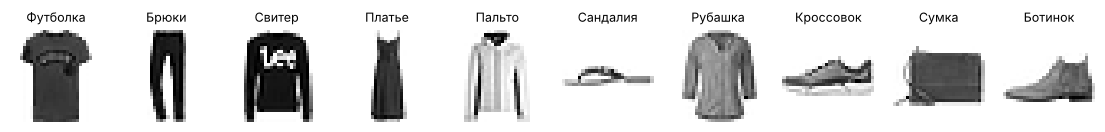

In [3]:
fig, axes = plt.subplots(1, 10, figsize=(14, 1.9))
for c, ax in enumerate(axes):
    i = int((test_set.targets == c).nonzero()[0])     # первая картинка класса c
    ax.imshow(test_set.data[i], cmap="gray_r")
    ax.set_title(CLASSES[c], fontsize=9)
    ax.axis("off")
plt.show()

## 2. Что делает одна свёртка

Возьмём ботинок и свернём его с **ядром Собеля** — классическим детектором вертикальных
границ. В CNN такие ядра не задаются вручную: сеть подбирает их сама при обучении.

вход: (1, 28, 28) → карта признаков: (28, 28)


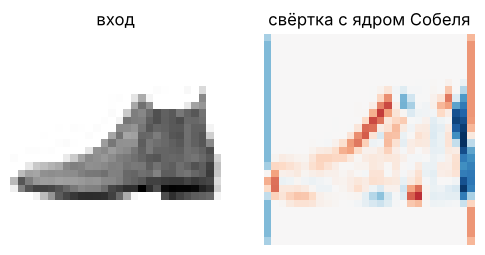

In [4]:
boot = test_set[0][0]                         # тензор 1×28×28 (тестовая картинка №0 — ботинок)
sobel = torch.tensor([[-1., 0., 1.],
                      [-2., 0., 2.],
                      [-1., 0., 1.]])

# conv2d ждёт вход N×C×H×W и ядра C_out×C_in×K×K
feature_map = F.conv2d(boot[None], sobel[None, None], padding=1)[0, 0]
print("вход:", tuple(boot.shape), "→ карта признаков:", tuple(feature_map.shape))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(6, 3))
a1.imshow(boot[0], cmap="gray_r"); a1.set_title("вход"); a1.axis("off")
lim = feature_map.abs().max()
a2.imshow(feature_map, cmap="RdBu_r", vmin=-lim, vmax=lim)
a2.set_title("свёртка с ядром Собеля"); a2.axis("off")
plt.show()

## 3. Модель SimpleCNN

Сеть состоит из двух частей:

* **features** — два свёрточных блока «свёртка → BatchNorm → ReLU → MaxPool». Они превращают
  картинку в 64 карты признаков 7×7;
* **classifier** — полносвязные слои, которые по признакам выбирают класс.

`BatchNorm` нормирует каждую карту по мини-батчу (среднее 0, дисперсия 1) — обучение быстрее
и стабильнее. `Dropout(0.3)` при обучении случайно обнуляет 30 % нейронов — это мешает сети
запоминать обучающую выборку (переобучаться).

In [5]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),   # 32 фильтра 3×3   → 32×28×28
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),                              # уменьшение вдвое → 32×14×14
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # 64 фильтра 32×3×3 → 64×14×14
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),                              #                  → 64×7×7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                 # 64×7×7 → вектор из 3136 чисел
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, n_classes),                    # 10 логитов
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = SimpleCNN()

# Прогоним одну картинку и посмотрим форму после каждого слоя
x = torch.zeros(1, 1, 28, 28)
print(f"{'слой':<14}{'выход':<16}{'параметров':>11}")
for layer in [*model.features, *model.classifier]:
    x = layer(x)
    n = sum(p.numel() for p in layer.parameters())
    print(f"{layer.__class__.__name__:<14}{' × '.join(map(str, x.shape[1:])):<16}{n:>11,}")
print(f"\nВсего параметров: {sum(p.numel() for p in model.parameters()):,}")

слой          выход            параметров
Conv2d        32 × 28 × 28            320
BatchNorm2d   32 × 28 × 28             64
ReLU          32 × 28 × 28              0
MaxPool2d     32 × 14 × 14              0
Conv2d        64 × 14 × 14         18,496
BatchNorm2d   64 × 14 × 14            128
ReLU          64 × 14 × 14              0


MaxPool2d     64 × 7 × 7                0
Flatten       3136                      0
Linear        128                 401,536
ReLU          128                       0
Dropout       128                       0
Linear        10                    1,290

Всего параметров: 421,834


Почти все параметры (≈ 95 %) — в первом полносвязном слое `3136 → 128`. Свёрточные слои
очень экономны: у первого 32 · (1·9 + 1) = 320 параметров, у второго 64 · (32·9 + 1) = 18 496.

## 4. Обучение

На каждом мини-батче четыре шага:
1. **прямой проход** — сеть выдаёт логиты;
2. **функция потерь** — `CrossEntropyLoss` применяет softmax и считает кросс-энтропию;
3. **обратный проход** — `loss.backward()` считает градиенты по всем весам;
4. **шаг оптимизатора** — Adam сдвигает веса против градиента.

После каждой эпохи шаг обучения уменьшается по косинусу (`CosineAnnealingLR`, от 0,001 до 0):
в начале сеть учится быстро, в конце аккуратно доводит веса. Затем меряем точность на
валидации и запоминаем веса лучшей эпохи.

In [6]:
def run_epoch(model, loader, optimizer=None):
    # Одна эпоха. С optimizer — обучение, без него — только оценка.
    training = optimizer is not None
    model.train(training)                        # Dropout/BatchNorm: режим обучения или оценки
    loss_fn = nn.CrossEntropyLoss()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):       # при оценке градиенты не считаем
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)               # 1. прямой проход
            loss = loss_fn(logits, labels)       # 2. функция потерь
            if training:
                optimizer.zero_grad()
                loss.backward()                  # 3. обратный проход
                optimizer.step()                 # 4. шаг оптимизатора
            total_loss += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            n += len(labels)
    return total_loss / n, correct / n

In [7]:
torch.manual_seed(SEED)
model = SimpleCNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 12
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_acc, best_state = 0.0, None

for epoch in range(1, EPOCHS + 1):
    t0 = time.perf_counter()
    tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
    scheduler.step()                               # уменьшаем шаг обучения
    va_loss, va_acc = run_epoch(model, val_loader)
    for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
        history[k].append(v)
    if va_acc > best_acc:                          # запоминаем лучшую эпоху
        best_acc, best_state = va_acc, copy.deepcopy(model.state_dict())
    print(f"эпоха {epoch:2d}: loss {tr_loss:.4f} / {va_loss:.4f}   "
          f"accuracy {tr_acc:.4f} / {va_acc:.4f}   ({time.perf_counter() - t0:.0f} с)")

model.load_state_dict(best_state)
print(f"\nлучшая точность на валидации: {best_acc:.4f}")

эпоха  1: loss 0.4534 / 0.2912   accuracy 0.8379 / 0.8924   (53 с)


эпоха  2: loss 0.3073 / 0.2553   accuracy 0.8895 / 0.9098   (47 с)


эпоха  3: loss 0.2647 / 0.2522   accuracy 0.9035 / 0.9074   (35 с)


эпоха  4: loss 0.2352 / 0.2329   accuracy 0.9129 / 0.9182   (35 с)


эпоха  5: loss 0.2117 / 0.2348   accuracy 0.9229 / 0.9148   (33 с)


эпоха  6: loss 0.1890 / 0.2232   accuracy 0.9315 / 0.9194   (34 с)


... (2 outputs left out)

эпоха  9: loss 0.1352 / 0.1999   accuracy 0.9512 / 0.9338   (33 с)


эпоха 10: loss 0.1215 / 0.2004   accuracy 0.9559 / 0.9298   (36 с)


эпоха 11: loss 0.1122 / 0.1998   accuracy 0.9601 / 0.9304   (33 с)


эпоха 12: loss 0.1072 / 0.1996   accuracy 0.9623 / 0.9314   (34 с)

лучшая точность на валидации: 0.9338


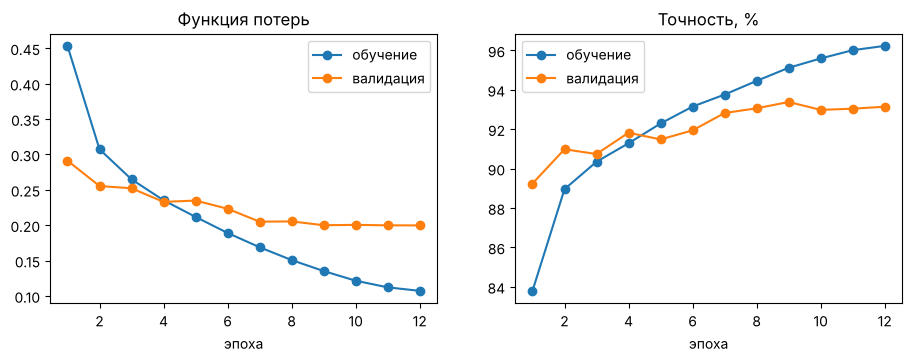

In [8]:
epochs = range(1, EPOCHS + 1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(epochs, history["train_loss"], "-o", label="обучение")
a1.plot(epochs, history["val_loss"], "-o", label="валидация")
a1.set(title="Функция потерь", xlabel="эпоха"); a1.legend()
a2.plot(epochs, np.array(history["train_acc"]) * 100, "-o", label="обучение")
a2.plot(epochs, np.array(history["val_acc"]) * 100, "-o", label="валидация")
a2.set(title="Точность, %", xlabel="эпоха"); a2.legend()
plt.show()

Точность на обучении продолжает расти, а на валидации выходит на плато: сеть начинает
запоминать обучающие картинки (**переобучение**). Поэтому мы берём веса лучшей по валидации
эпохи, а не последней.

## 5. Оценка на тестовой выборке

In [9]:
test_loss, test_acc = run_epoch(model, test_loader)
print(f"точность на тесте: {test_acc:.4f}  ({round(test_acc * len(test_set))} из {len(test_set)})")

# Матрица ошибок: строка — истинный класс, столбец — ответ сети
model.eval()
with torch.no_grad():
    preds = torch.cat([model(x.to(device)).argmax(1).cpu() for x, _ in test_loader])
cm = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(test_set.targets, preds):
    cm[t, p] += 1

print("\nточность по классам:")
for c in (cm.diag() / cm.sum(1)).argsort():
    print(f"  {CLASSES[c]:<10} {cm[c, c] / cm[c].sum():.3f}")

точность на тесте: 0.9252  (9252 из 10000)



точность по классам:
  Рубашка    0.756
  Свитер     0.873
  Футболка   0.886
  Пальто     0.906
  Платье     0.928
  Ботинок    0.963
  Кроссовок  0.978
  Сумка      0.979
  Брюки      0.988
  Сандалия   0.995


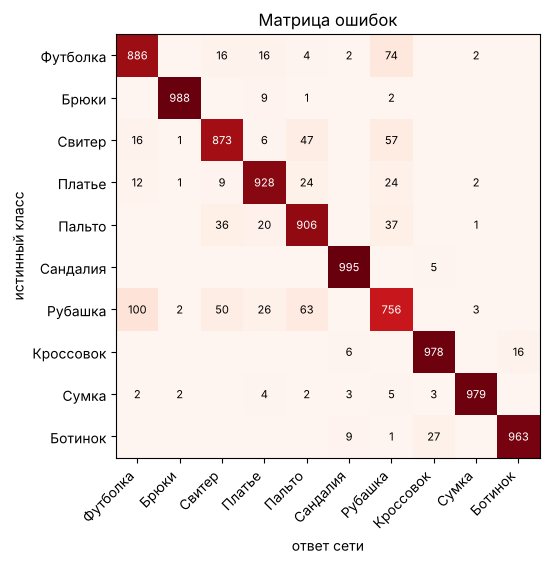

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(cm, cmap="Reds")
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 500 else "black")
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(10), CLASSES)
ax.set(xlabel="ответ сети", ylabel="истинный класс", title="Матрица ошибок")
plt.show()

Сложнее всего различать верх одежды: рубашку путают с футболкой, пальто и свитером.
Обувь и сумки сеть различает почти без ошибок.

## 6. Что видит сеть: карты признаков

Подадим ботинок и посмотрим на выходы первого свёрточного блока (после ReLU) —
32 карты 28×28. Каждая карта показывает, где на картинке найден «свой» признак.

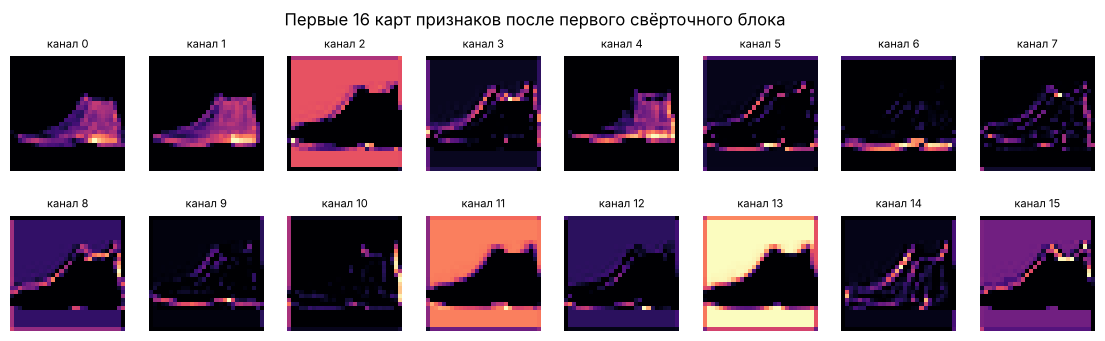

In [11]:
with torch.no_grad():
    maps = model.features[:3](boot[None].to(device))[0].cpu()   # Conv → BN → ReLU: 32×28×28

fig, axes = plt.subplots(2, 8, figsize=(14, 3.8))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(maps[k], cmap="magma")
    ax.set_title(f"канал {k}", fontsize=8)
    ax.axis("off")
plt.suptitle("Первые 16 карт признаков после первого свёрточного блока")
plt.show()

## Итоги

* Свёрточная сеть из двух блоков и ≈ 422 тыс. параметров правильно классифицирует ≈ 92 %
  незнакомых картинок Fashion-MNIST.
* Первый слой выучил детекторы простых признаков — контуров, краёв, подошвы, — второй
  комбинирует их в части вещей.
* Что дальше: аугментация данных (случайные сдвиги и отражения при обучении) обычно добавляет
  ещё 1–2 %, а для реальных задач с небольшим набором данных берут предобученную сеть и
  дообучают её (transfer learning).

Подробный разбор, численный пример и сравнение с другими методами — в скриптах `01…08`
и в презентации.